# Adaptive Conformal Prediction

Regular conformal prediction uses one fixed cushion learned from a calibration set.
That didn't fully fix our coverage gap, likely because Sensex's behavior shifts
over time (not exchangeable).

Adaptive conformal prediction (Gibbs & Candes, 2021) fixes this by adjusting the
cushion continuously, based on recent performance, instead of freezing it once.

In [1]:
import numpy as np

In [2]:
forecasts = np.load("../data/forecasts.npy")
actuals = np.load("../data/actuals.npy")

day = 15
quantile_levels = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

day_forecasts = forecasts[:, day, :]
day_actuals = actuals[:, day]

lower = day_forecasts[:, 1]   # 10th percentile
upper = day_forecasts[:, 9]   # 90th percentile

lower.shape, upper.shape

((352,), (352,))

## Same time split as before

First part is used as starting history, the rest is where we test the
adaptive method, moving forward one point at a time.

In [3]:
n = len(day_actuals)
split_point = int(n * 0.6)

cal_lower, test_lower = lower[:split_point], lower[split_point:]
cal_upper, test_upper = upper[:split_point], upper[split_point:]
cal_actuals, test_actuals = day_actuals[:split_point], day_actuals[split_point:]

len(cal_actuals), len(test_actuals)

(211, 141)

## Set up the starting scores and starting alpha

alpha = 0.2 means we are targeting 80% coverage (1 - alpha).

We start our score history from the calibration set, same as before.

In [4]:
target_alpha = 0.2   # want 80% coverage
gamma = 0.01          # how fast alpha adjusts, small = slow and steady

alpha_t = target_alpha

# conformity scores from the calibration set, same formula as before
score_history = list(np.maximum(cal_lower - cal_actuals, cal_actuals - cal_upper))

len(score_history)

211

## Run through the test set, one point at a time

At each step:
1. use current alpha_t to pick a cushion from recent score history
2. build the interval for this point
3. check if it covered the actual value
4. update alpha_t based on whether we covered or not
5. add this point's own score to history, for future steps

In [5]:
covered_list = []
alpha_history = []
width_list = []

for i in range(len(test_actuals)):

    # clip alpha so it stays in a sane range
    alpha_t = np.clip(alpha_t, 0.01, 0.5)

    # pick cushion using current alpha_t
    q_t = np.quantile(score_history, 1 - alpha_t)

    lo = test_lower[i] - q_t
    hi = test_upper[i] + q_t

    actual = test_actuals[i]
    covered = (actual >= lo) and (actual <= hi)

    covered_list.append(covered)
    alpha_history.append(alpha_t)
    width_list.append(hi - lo)

    # update alpha: if we missed, alpha goes down (demand wider next time)
    # if we covered, alpha goes up a little (can afford to loosen)
    err_t = 0 if covered else 1
    alpha_t = alpha_t + gamma * (target_alpha - err_t)

    # add this point's score to history so future steps can use it
    this_score = max(test_lower[i] - actual, actual - test_upper[i])
    score_history.append(this_score)

print("done")

done


## Check the result: coverage and width, adaptive vs before

In [6]:
adaptive_coverage = np.mean(covered_list)
adaptive_avg_width = np.mean(width_list)

print("target coverage:", 1 - target_alpha)
print("adaptive coverage:", round(adaptive_coverage * 100, 1), "%")
print("adaptive avg width:", round(adaptive_avg_width, 2))

target coverage: 0.8
adaptive coverage: 78.7 %
adaptive avg width: 5630.05


Compare this to the earlier fixed conformal prediction result:
- before correction: 75.2% coverage
- fixed conformal correction: 78.0% coverage, width 5387.22
- adaptive conformal correction: see above

## Plot how alpha changed over time

This shows the method adjusting itself as it goes.

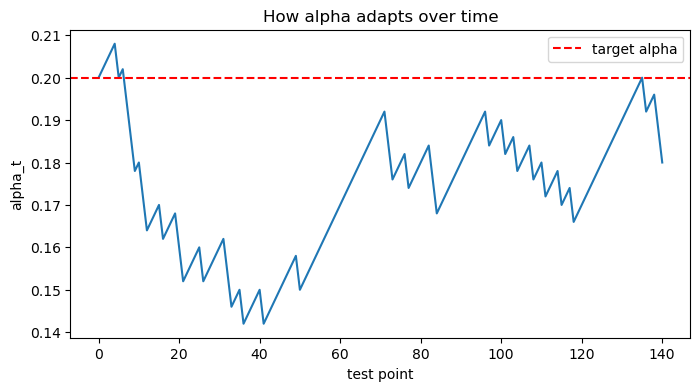

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(alpha_history)
plt.axhline(target_alpha, color="red", linestyle="--", label="target alpha")
plt.xlabel("test point")
plt.ylabel("alpha_t")
plt.title("How alpha adapts over time")
plt.legend()
plt.show()

## Adaptive Conformal Prediction

Standard (fixed) conformal prediction improved coverage from 75.2% to 78.0%,
but did not fully close the gap to the 80% target. This is consistent with a
violation of the exchangeability assumption that conformal prediction relies on --
Sensex's statistical behavior likely shifts over time, so a single cushion learned
once from an early calibration period may not remain the right size later on.

Adaptive conformal prediction (Gibbs & Candes, 2021) addresses this by updating
the interval width continuously, based on recent coverage performance, instead of
fixing it once. At each new test point, the target miscoverage rate `alpha_t` is
adjusted: if the previous point was missed, `alpha_t` decreases (demanding wider
intervals going forward); if it was covered, `alpha_t` increases slightly (allowing
intervals to loosen).

**Results (day 16 ahead forecast, same test set as before):**

| Method | Coverage | Avg. interval width |
|---|---|---|
| No correction | 75.2% | 5152.03 |
| Fixed conformal prediction | 78.0% | 5387.22 (+4.6%) |
| Adaptive conformal prediction | 78.7% | 5630.05 (+9.3%) |

Adaptive conformal prediction achieved slightly better coverage than the fixed
version, at the cost of wider intervals on average. This is a reasonable trade-off:
adaptive correction is not a free improvement, it buys marginally better reliability
at a real cost in interval width.

**Alpha over time:** plotting `alpha_t` across the test set shows the method
actively self-correcting. It drops sharply in the first ~10 points (demanding wider
intervals after early misses), then settles into a repeating pattern, rising after
good coverage and falling back after a miss, oscillating mostly between 0.14 and
0.19 rather than staying fixed at the 0.20 target. This shows the mechanism working
as intended, though the oscillation stays somewhat below the target level rather
than converging exactly to it -- likely because the adjustment step size (`gamma`)
is not fully tuned, or the test period (141 points) is not quite long enough for
full convergence. This is a reasonable limitation to note rather than a failure of
the method.

**Conclusion:** Both conformal prediction variants improve on the raw Chronos-2
intervals, with adaptive conformal prediction providing a small additional gain by
responding to distribution shift over time. Neither fully closes the gap to the
80% target, suggesting Sensex's non-stationary behavior remains a genuine challenge
for calibrating foundation model forecasts, and further gains would likely require
either a longer test period, a tuned adjustment rate, or a more sophisticated
adaptive method.